# Day 13 – RAG: Chat with your documents

**Goal:** build a question-answering assistant that answers only from a set of documents, cites its sources, and says "I don't know" when the answer is not there.

**Documents:** 5 well-known AI papers from arXiv (Transformer, BERT, RAG, Sentence-BERT, LoRA).

**Plan**
1. Load the PDFs and split them into chunks (2 strategies: fixed-size vs recursive)
2. Embed the chunks (MiniLM) and store them in a FAISS vector index
3. Retrieve top-10, re-rank with a cross-encoder, keep top-3, answer with Gemini + citations
4. Evaluate on 25 questions: retrieval hit rate, faithfulness, relevance, "I don't know" behaviour




## 0. Setup

In [1]:
!pip install -q faiss-cpu pypdf google-genai

import os, re, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from pypdf import PdfReader

CHUNK_SIZE = 800      # characters per chunk
OVERLAP = 100         # overlap for the fixed-size strategy
TOP_K = 10            # chunks taken from the vector index
TOP_N = 3             # chunks kept after re-ranking (sent to the LLM)
RPM = 10              # max Gemini calls per minute (free tier is safe at 10)

## 1. Load the documents
Each PDF is read **page by page**, so every chunk remembers its paper and page number (needed for citations).

In [2]:
PAPERS = {
    "Transformer (Attention Is All You Need)": "1706.03762",
    "BERT": "1810.04805",
    "RAG (Lewis et al.)": "2005.11401",
    "Sentence-BERT": "1908.10084",
    "LoRA": "2106.09685",
}

os.makedirs("docs", exist_ok=True)

def download(arxiv_id):
    path = f"docs/{arxiv_id}.pdf"
    if os.path.exists(path) and os.path.getsize(path) > 10_000:
        return path
    for url in [f"https://arxiv.org/pdf/{arxiv_id}", f"https://export.arxiv.org/pdf/{arxiv_id}"]:
        try:
            r = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=60)
            if r.ok and r.content[:4] == b"%PDF":
                open(path, "wb").write(r.content)
                return path
        except Exception as e:
            print("  failed:", url, e)
        time.sleep(3)
    raise RuntimeError(f"Could not download {arxiv_id}")

def clean(text):
    text = re.sub(r"-\n(\w)", r"\1", text)      # join words broken over lines
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

pages = []   # one row per page
for name, arxiv_id in PAPERS.items():
    reader = PdfReader(download(arxiv_id))
    for i, p in enumerate(reader.pages):
        t = clean(p.extract_text() or "")
        if len(t) > 50:
            pages.append({"doc": name, "page": i + 1, "text": t})
    print(f"{name}: {len(reader.pages)} pages")

print("Total pages with text:", len(pages))

Transformer (Attention Is All You Need): 15 pages
BERT: 16 pages
RAG (Lewis et al.): 19 pages
Sentence-BERT: 11 pages
LoRA: 26 pages
Total pages with text: 87


## 2. Chunking – two strategies
- **Fixed-size:** cut every `CHUNK_SIZE` characters with a small overlap. Simple, but it can cut a sentence in half.
- **Recursive:** try to split on paragraphs first, then lines, then sentences, then words, and merge small pieces back together up to `CHUNK_SIZE`. Chunks keep whole sentences.

In [3]:
def fixed_chunks(text, size=CHUNK_SIZE, overlap=OVERLAP):
    out, start = [], 0
    while start < len(text):
        out.append(text[start:start + size])
        start += size - overlap
    return out

def recursive_chunks(text, size=CHUNK_SIZE, seps=("\n\n", "\n", ". ", " ")):
    if len(text) <= size:
        return [text]
    sep = next((s for s in seps if s in text), None)
    if sep is None:
        return fixed_chunks(text, size, 0)
    pieces = [p + sep for p in text.split(sep)]
    out, cur = [], ""
    for p in pieces:
        if len(p) > size:                      # piece itself too big -> split it with the next separator
            if cur: out.append(cur); cur = ""
            out.extend(recursive_chunks(p, size, seps[seps.index(sep) + 1:] or (" ",)))
        elif len(cur) + len(p) <= size:
            cur += p
        else:
            out.append(cur); cur = p
    if cur: out.append(cur)
    return [c.strip() for c in out if c.strip()]

def make_chunks(splitter):
    rows = []
    for pg in pages:
        for c in splitter(pg["text"]):
            if len(c) > 40:
                rows.append({"doc": pg["doc"], "page": pg["page"], "text": c})
    return pd.DataFrame(rows)

chunk_sets = {"fixed": make_chunks(fixed_chunks), "recursive": make_chunks(recursive_chunks)}

for name, df in chunk_sets.items():
    print(f"{name:10s} chunks: {len(df):4d}   avg length: {df.text.str.len().mean():.0f} chars")

print("\nExample fixed chunk end:     ...", chunk_sets["fixed"].text.iloc[3][-80:].replace("\n", " "))
print("Example recursive chunk end: ...", chunk_sets["recursive"].text.iloc[3][-80:].replace("\n", " "))

fixed      chunks:  468   avg length: 717 chars
recursive  chunks:  434   avg length: 685 chars

Example fixed chunk end:     ...  Systems (NIPS 2017), Long Beach, CA, USA. arXiv:1706.03762v7 [cs.CL] 2 Aug 2023
Example recursive chunk end: ...  Systems (NIPS 2017), Long Beach, CA, USA. arXiv:1706.03762v7 [cs.CL] 2 Aug 2023


## 3. Embeddings + vector store (FAISS)
`all-MiniLM-L6-v2` turns each chunk into a 384-number vector. Vectors are normalised, so the inner product in FAISS = cosine similarity.

In [4]:
from sentence_transformers import SentenceTransformer, CrossEncoder
import faiss

embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")
reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2", device="cpu")

indexes = {}
for name, df in chunk_sets.items():
    t0 = time.time()
    vecs = embedder.encode(df.text.tolist(), batch_size=32, normalize_embeddings=True,
                           show_progress_bar=False).astype("float32")
    index = faiss.IndexFlatIP(vecs.shape[1])
    index.add(vecs)
    indexes[name] = index
    print(f"{name}: {index.ntotal} vectors, dim {vecs.shape[1]}, {time.time() - t0:.0f}s")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (12 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

fixed: 468 vectors, dim 384, 34s
recursive: 434 vectors, dim 384, 36s


## 4. Retrieval + re-ranking
1. FAISS gives the `TOP_K` most similar chunks (fast, but rough).
2. The cross-encoder reads the question and each chunk **together** and gives a better score. We keep the best `TOP_N`.

In [5]:
def retrieve(question, strategy="recursive", k=TOP_K, n=TOP_N, rerank=True):
    df = chunk_sets[strategy]
    q = embedder.encode([question], normalize_embeddings=True).astype("float32")
    scores, ids = indexes[strategy].search(q, k)
    hits = df.iloc[ids[0]].copy()
    hits["vec_score"] = scores[0]
    if rerank:
        hits["rerank_score"] = reranker.predict([(question, t) for t in hits.text])
        hits = hits.sort_values("rerank_score", ascending=False)
    return hits.head(n)

retrieve("How many attention heads does the Transformer use?")[["doc", "page", "text"]]

,doc,page,text
18,Transformer (Attention Is All You Need),5,3.2.3 Applications of Attention in our Model\n...
107,BERT,8,"hidden units, and attention heads, while other..."
77,BERT,3,Model Architecture BERT’s model architecture i...


## 5. Generation with citations (Gemini)
The prompt tells the model to use **only** the context, cite sources like `[2]`, and reply exactly `I don't know` if the answer is not in the context.
If no API key is found, Colab's built-in model is used instead.

In [6]:
client, MODEL, colab_ai = None, None, None
try:
    from google.colab import userdata
    key = userdata.get("GEMINI_API_KEY")
except Exception:
    key = os.environ.get("GEMINI_API_KEY")

if key:
    from google import genai
    client = genai.Client(api_key=key)
    available = [m.name.split("/")[-1] for m in client.models.list()]
    MODEL = next((m for m in ["gemini-2.5-flash", "gemini-2.0-flash", "gemini-flash-latest"] if m in available), "gemini-2.5-flash")
    print("Using Gemini API model:", MODEL)
else:
    from google.colab import ai as colab_ai
    print("No GEMINI_API_KEY found -> using Colab built-in model")

_last_call = [0.0]
def llm(prompt):
    wait = 60 / RPM - (time.time() - _last_call[0])
    if wait > 0: time.sleep(wait)
    for attempt in range(4):
        try:
            _last_call[0] = time.time()
            if client:
                return client.models.generate_content(model=MODEL, contents=prompt).text.strip()
            return colab_ai.generate_text(prompt).strip()
        except Exception as e:
            print("  LLM error, retrying in 30s:", str(e)[:80])
            time.sleep(30)
    return "ERROR"

PROMPT = """Answer the question using ONLY the context below.
- Cite the sources you used with their numbers, like [1] or [2][3].
- Keep the answer short (1-3 sentences).
- If the context does not contain the answer, reply exactly: I don't know

Context:
{context}

Question: {question}
Answer:"""

def ask(question, strategy="recursive", show=True):
    hits = retrieve(question, strategy)
    context = "\n\n".join(f"[{i+1}] ({r.doc}, page {r.page})\n{r.text}" for i, r in enumerate(hits.itertuples()))
    answer = llm(PROMPT.format(context=context, question=question))
    sources = [f"[{i+1}] {r.doc}, p.{r.page}" for i, r in enumerate(hits.itertuples())]
    if show:
        print("Q:", question)
        print("A:", answer)
        print("Sources:", *sources, sep="\n  ")
    return answer, hits, context

_ = ask("What two pre-training tasks does BERT use?")
print()
_ = ask("What is the internship leave policy at Duovate?")

No GEMINI_API_KEY found -> using Colab built-in model
Q: What two pre-training tasks does BERT use?
A: BERT uses the "masked LM" (MLM) and "next sentence prediction" (NSP) pre-training tasks [1][3].
Sources:
  [1] BERT, p.14
  [2] BERT, p.3
  [3] BERT, p.8

Q: What is the internship leave policy at Duovate?
A: I don't know
Sources:
  [1] Sentence-BERT, p.3
  [2] Sentence-BERT, p.7
  [3] Sentence-BERT, p.7


## 6. Test set (25 questions)
20 questions that the papers can answer, and 5 that they **cannot** (the assistant should say "I don't know").
`evidence` = words that must appear in a retrieved chunk for it to count as a correct retrieval.

In [7]:
TEST = [
    # question, expected answer, source paper, evidence keywords
    ("How many layers are in the Transformer encoder stack?", "6 identical layers (N = 6)", "Transformer (Attention Is All You Need)", ["N = 6", "N=6", "six"]),
    ("What BLEU score did the big Transformer get on WMT 2014 English-to-German?", "28.4 BLEU", "Transformer (Attention Is All You Need)", ["28.4"]),
    ("What is the model dimension d_model of the base Transformer?", "512", "Transformer (Attention Is All You Need)", ["512"]),
    ("How many parallel attention heads does the base Transformer use?", "8 heads (h = 8)", "Transformer (Attention Is All You Need)", ["h = 8", "h=8", "8 parallel"]),
    ("Which optimizer was used to train the Transformer?", "Adam", "Transformer (Attention Is All You Need)", ["Adam"]),
    ("What are the two pre-training tasks of BERT?", "Masked language model (MLM) and next sentence prediction (NSP)", "BERT", ["next sentence prediction", "NSP"]),
    ("What percentage of tokens does BERT mask during pre-training?", "15%", "BERT", ["15%"]),
    ("How many parameters does BERT-Large have?", "340M", "BERT", ["340M"]),
    ("Which corpora were used to pre-train BERT?", "BooksCorpus (800M words) and English Wikipedia (2,500M words)", "BERT", ["BooksCorpus"]),
    ("What retriever does the RAG model use?", "Dense Passage Retriever (DPR), a bi-encoder", "RAG (Lewis et al.)", ["DPR", "Dense Passage"]),
    ("What are the two RAG model variants?", "RAG-Sequence and RAG-Token", "RAG (Lewis et al.)", ["RAG-Sequence", "RAG-Token"]),
    ("Which pre-trained model is the generator in RAG?", "BART-large", "RAG (Lewis et al.)", ["BART"]),
    ("Which knowledge source is used as the non-parametric memory in RAG?", "A Wikipedia dump (Dec 2018) split into 100-word chunks, about 21M documents", "RAG (Lewis et al.)", ["Wikipedia"]),
    ("How long does BERT take to find the most similar pair in 10,000 sentences, compared to SBERT?", "About 65 hours with BERT vs about 5 seconds with SBERT", "Sentence-BERT", ["65 hours"]),
    ("What is the default pooling strategy in SBERT?", "MEAN pooling", "Sentence-BERT", ["MEAN", "mean"]),
    ("Which datasets were used to train SBERT?", "SNLI and Multi-Genre NLI (MultiNLI)", "Sentence-BERT", ["SNLI"]),
    ("By how much does LoRA reduce the number of trainable parameters compared to full GPT-3 fine-tuning?", "About 10,000 times fewer trainable parameters (and 3 times less GPU memory)", "LoRA", ["10,000"]),
    ("Which attention weight matrices does LoRA adapt in the experiments?", "The query and value projections (W_q and W_v)", "LoRA", ["W_q", "Wq", "query"]),
    ("Does LoRA add inference latency?", "No, the low-rank matrices can be merged into the weights, so no extra latency", "LoRA", ["latency"]),
    ("What is the largest model LoRA was applied to in the paper?", "GPT-3 175B", "LoRA", ["175B", "GPT-3"]),
    # not answerable from the documents
    ("What is the internship leave policy at Duovate?", "I don't know", None, []),
    ("Who won the 2022 FIFA World Cup?", "I don't know", None, []),
    ("How many parameters does GPT-4 have?", "I don't know", None, []),
    ("What is the price of an NVIDIA A100 GPU in Sri Lanka?", "I don't know", None, []),
    ("What is the capital of Australia?", "I don't know", None, []),
]
test = pd.DataFrame(TEST, columns=["question", "expected", "source", "evidence"])
test["answerable"] = test.source.notna()
print(test.answerable.value_counts().rename({True: "answerable", False: "not answerable"}))

# Sanity check: does every evidence keyword exist in its paper? (PDF text extraction can change symbols)
full = {d: " ".join(p["text"] for p in pages if p["doc"] == d).lower() for d in PAPERS}
for r in test[test.answerable].itertuples():
    if not any(e.lower() in full[r.source] for e in r.evidence):
        print("WARNING evidence not found in text ->", r.question)

answerable
answerable        20
not answerable     5
Name: count, dtype: int64


## 7. Retrieval evaluation – hit rate
A question is a **hit** if at least one of the top-3 chunks comes from the right paper **and** contains an evidence keyword.
We compare: fixed vs recursive chunking, and with vs without re-ranking. (No LLM calls here, so it is fast.)

,chunking,re-rank,hit_rate@3
0,fixed,False,0.55
1,fixed,True,0.80
2,recursive,False,0.65
3,recursive,True,0.80


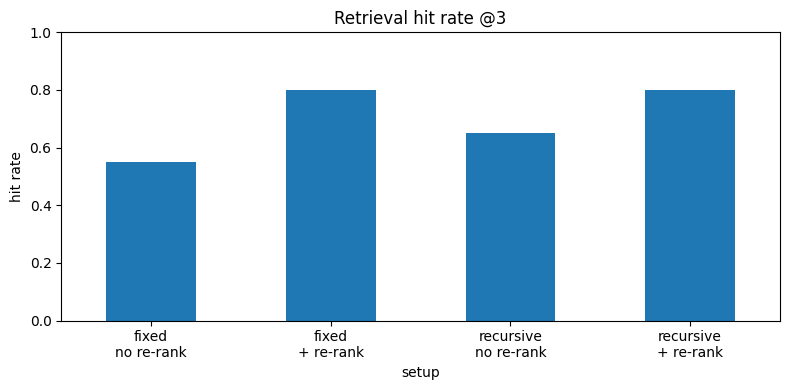

Best chunking strategy (with re-rank): recursive


In [8]:
def is_hit(hits, source, evidence):
    for r in hits.itertuples():
        if r.doc == source and any(e.lower() in r.text.lower() for e in evidence):
            return True
    return False

rows = []
answerable = test[test.answerable]
for strategy in chunk_sets:
    for rerank in [False, True]:
        h = [is_hit(retrieve(r.question, strategy, rerank=rerank), r.source, r.evidence) for r in answerable.itertuples()]
        rows.append({"chunking": strategy, "re-rank": rerank, "hit_rate@3": np.mean(h)})
retrieval_results = pd.DataFrame(rows)
display(retrieval_results)

retrieval_results.assign(setup=retrieval_results.chunking + "\n" + retrieval_results["re-rank"].map({True: "+ re-rank", False: "no re-rank"})) \
    .plot.bar(x="setup", y="hit_rate@3", legend=False, ylim=(0, 1), rot=0, title="Retrieval hit rate @3", figsize=(8, 4))
plt.ylabel("hit rate"); plt.tight_layout(); plt.show()

best = retrieval_results[retrieval_results["re-rank"]].sort_values("hit_rate@3").iloc[-1]["chunking"]
print("Best chunking strategy (with re-rank):", best)

## 8. Answer evaluation – faithfulness and relevance
For all 25 questions we generate an answer with the best setup, then use the LLM as a **judge**:
- **Faithfulness (1-5):** is every claim in the answer supported by the retrieved context? (no hallucination)
- **Relevance (1-5):** does the answer actually answer the question?

We also check the "I don't know" behaviour. About 50 LLM calls, roughly 5-6 minutes.

In [9]:
JUDGE = """You are grading a RAG system. Return ONLY JSON like {{"faithfulness": 1-5, "relevance": 1-5}}.
faithfulness: 5 = every claim in the answer is supported by the context, 1 = mostly unsupported.
relevance: 5 = fully answers the question, 1 = does not answer it.
If the answer is "I don't know": faithfulness = 5; relevance = 5 if the context really lacks the answer, else 1.

Context:
{context}

Question: {question}
Answer: {answer}"""

def judge(question, answer, context):
    raw = llm(JUDGE.format(context=context, question=question, answer=answer))
    m = re.search(r"\{.*?\}", raw, flags=re.S)
    try:
        d = json.loads(m.group(0))
        return int(d["faithfulness"]), int(d["relevance"])
    except Exception:
        return np.nan, np.nan

RESULTS_FILE = "day13_answers.csv"
done = pd.read_csv(RESULTS_FILE) if os.path.exists(RESULTS_FILE) else pd.DataFrame(columns=["question"])
rows = done.to_dict("records")

for i, r in enumerate(test.itertuples()):
    if r.question in set(done.question):
        continue
    answer, hits, context = ask(r.question, best, show=False)
    f, rel = judge(r.question, answer, context)
    rows.append({"question": r.question, "expected": r.expected, "answer": answer,
                 "answerable": r.answerable, "retrieval_hit": is_hit(hits, r.source, r.evidence) if r.answerable else None,
                 "said_idk": "i don't know" in answer.lower() or "i do not know" in answer.lower(),
                 "faithfulness": f, "relevance": rel})
    pd.DataFrame(rows).to_csv(RESULTS_FILE, index=False)     # saved after every question (safe to re-run)
    print(f"{i+1}/{len(test)} done")

ans = pd.DataFrame(rows)
ans.head()

1/25 done
2/25 done
3/25 done
4/25 done
5/25 done
6/25 done
7/25 done
8/25 done
9/25 done
10/25 done
11/25 done
12/25 done
13/25 done
14/25 done
15/25 done
16/25 done
17/25 done
18/25 done
19/25 done
20/25 done
21/25 done
22/25 done
23/25 done
24/25 done
25/25 done


,question,expected,answer,answerable,retrieval_hit,said_idk,faithfulness,relevance
0,How many layers are in the Transformer encoder...,6 identical layers (N = 6),The Transformer encoder is composed of a stack...,True,True,False,5,5
1,What BLEU score did the big Transformer get on...,28.4 BLEU,On the WMT 2014 English-to-German translation ...,True,True,False,5,5
2,What is the model dimension d_model of the bas...,512,The model dimension $d_{\text{model}}$ of the ...,True,True,False,5,5
3,How many parallel attention heads does the bas...,8 heads (h = 8),The Transformer employs $h = 8$ parallel atten...,True,True,False,5,5
4,Which optimizer was used to train the Transfor...,Adam,A large Transformer was trained with the Adam ...,True,False,False,5,5


## 9. Results summary

,score
Retrieval hit rate @3 (best setup),0.8
Avg faithfulness (1-5),5.0
Avg relevance (1-5),5.0
Answerable Qs answered (not 'I don't know'),0.8
Unanswerable Qs correctly said 'I don't know',1.0


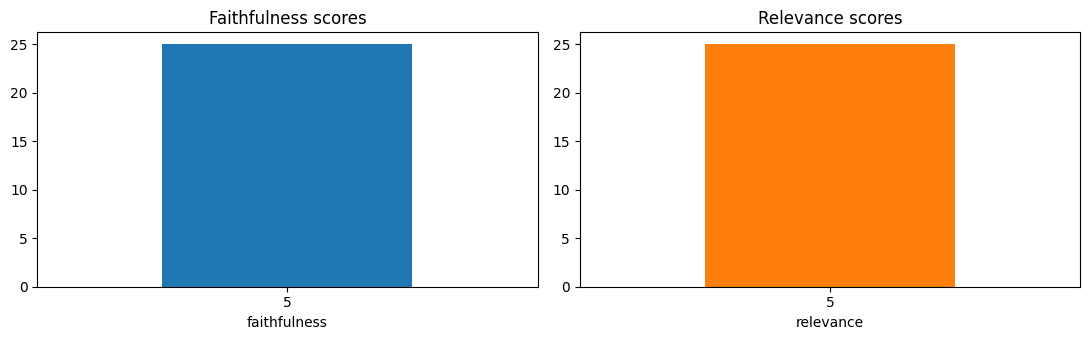

Answers to check by hand (low score, wrong 'I don't know', or retrieval miss):


,question,expected,answer,retrieval_hit,faithfulness,relevance
4,Which optimizer was used to train the Transformer?,Adam,"A large Transformer was trained with the Adam optimizer [3], while AdamW was used for GPT-3 adaptation methods [1].",False,5,5
6,What percentage of tokens does BERT mask during pre-training?,15%,I don't know,False,5,5
14,What is the default pooling strategy in SBERT?,MEAN pooling,I don't know,True,5,5
15,Which datasets were used to train SBERT?,SNLI and Multi-Genre NLI (MultiNLI),"SBERT was trained using the STSb dataset, or first pretrained on NLI datasets and then fine-tuned on the STSb datase...",False,5,5
16,By how much does LoRA reduce the number of trainable parameters compared to full GPT-3 fine-tuning?,"About 10,000 times fewer trainable parameters (and 3 times less GPU memory)",I don't know,True,5,5
19,What is the largest model LoRA was applied to in the paper?,GPT-3 175B,I don't know,False,5,5


In [10]:
a = ans[ans.answerable == True]
u = ans[ans.answerable == False]

summary = pd.Series({
    "Retrieval hit rate @3 (best setup)": a.retrieval_hit.astype(bool).mean(),
    "Avg faithfulness (1-5)": ans.faithfulness.mean(),
    "Avg relevance (1-5)": ans.relevance.mean(),
    "Answerable Qs answered (not 'I don't know')": 1 - a.said_idk.mean(),
    "Unanswerable Qs correctly said 'I don't know'": u.said_idk.mean(),
}).round(2)
display(summary.to_frame("score"))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ans.faithfulness.value_counts().sort_index().plot.bar(ax=ax[0], title="Faithfulness scores", rot=0)
ans.relevance.value_counts().sort_index().plot.bar(ax=ax[1], title="Relevance scores", rot=0, color="tab:orange")
plt.tight_layout(); plt.show()

pd.set_option("display.max_colwidth", 120)
print("Answers to check by hand (low score, wrong 'I don't know', or retrieval miss):")
problems = ans[(ans.faithfulness < 4) | (ans.relevance < 4) |
               ((ans.answerable == True) & (ans.said_idk)) |
               ((ans.answerable == False) & (~ans.said_idk.astype(bool))) |
               (ans.retrieval_hit == False)]
display(problems[["question", "expected", "answer", "retrieval_hit", "faithfulness", "relevance"]])

## 10. Try your own questions

In [11]:
_ = ask("Why does the Transformer use positional encodings?")

Q: Why does the Transformer use positional encodings?
A: I don't know
Sources:
  [1] Transformer (Attention Is All You Need), p.5
  [2] Transformer (Attention Is All You Need), p.8
  [3] BERT, p.12


## My notes (write in your own words)

**What I learned about chunking (fixed vs recursive):**
Fixed-size chunking cuts every 800 characters, so it can break a sentence in the middle. Recursive chunking splits by paragraphs and sentences, so each chunk keeps its meaning.
Without re-ranking, recursive was better (65% vs 55% hit rate). With re-ranking, both reached 80%.
-

**Did re-ranking help? Why do I think so?**
Yes, it was the biggest improvement (+25 points for fixed, +15 for recursive).
FAISS only compares vectors, so it is fast but rough. The cross-encoder reads the question and the chunk together, so it understands better which chunk really answers the question.
-

**Where did the assistant fail, and why?** (look at the "Answers to check by hand" table)
4 answerable questions got “I don’t know” (BERT masking %, SBERT pooling, LoRA parameter reduction, largest LoRA model). In most cases the right chunk was not in the top 3, so the LLM correctly refused instead of guessing.
The SBERT training data answer was only partly correct.
The LLM judge gave 5/5 to everything, even wrong answers, so I can’t trust it alone and had to check by hand.
Good news: all 5 unanswerable questions got “I don’t know”, so there was no hallucination
-

**What I would improve next time:**
Send top-5 chunks to the LLM instead of top-3.
Use hybrid search (keywords + vectors) so exact numbers like “15%” are found.
Use smaller chunks for facts and numbers.
Use a stricter judge (or RAGAS) and a bigger test set.
-